# Drive Time Analytics – Python Analysis
**Purpose**
This notebook independently verifies selected findings from the Orange Data Mining analysis and extends the project through statistical diagnostics, regression analysis, multicollinearity testing, and residual analysis.

**Dataset:** DriveTime_Analytics_AI_Corrected_v1.3.xlsx

The dataset is fictional and AI-assisted and is used for educational analytics practice.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving DriveTime_Analytics_AI.xlsx to DriveTime_Analytics_AI.xlsx


**1. Data Import and Validation**
The dataset is loaded from the Excel workbook and checked for expected dimensions, missing values, and intentional Christmas store closures before statistical analysis.

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_excel(
    "DriveTime_Analytics_AI.xlsx",
    sheet_name="Drive Time Data"
)

In [ ]:
df.shape

(1826, 89)

In [ ]:
df.head()

,Date,FiscalYear,FiscalQuarter,FiscalMonth,FiscalWeek,DayOfWeek,WeekendFlag,MonthName,QuarterEndFlag,HolidayFlag,...,CrossTrainedPercent,ICAPCompletion,PricingAccuracy,PlanogramCompletion,TrainingCompliance,SafetyAudit,ShrinkPercent,StoreExecutionScore,AssociateEngagement,LeadershipEffectiveness
0,2021-01-01,2021,1,1,53,Friday,0,January,0,1,...,75.4,92.1,98.0,91.5,90.9,90.0,1.26,77.4,72.1,79.7
1,2021-01-02,2021,1,1,53,Saturday,1,January,0,0,...,81.9,92.8,93.0,87.9,88.7,94.5,1.22,68.5,69.4,71.0
2,2021-01-03,2021,1,1,53,Sunday,1,January,0,0,...,76.7,93.6,90.6,86.1,91.2,92.9,1.17,79.0,77.2,79.9
3,2021-01-04,2021,1,1,1,Monday,0,January,0,0,...,71.2,93.3,93.2,88.1,89.8,93.7,0.92,80.3,80.2,81.1
4,2021-01-05,2021,1,1,1,Tuesday,0,January,0,0,...,74.1,93.3,94.0,90.3,93.4,89.8,1.21,72.3,80.3,73.7


In [ ]:
df.isna().sum()

,0
Date,0
FiscalYear,0
FiscalQuarter,0
FiscalMonth,0
FiscalWeek,0
...,...
SafetyAudit,5
ShrinkPercent,5
StoreExecutionScore,5
AssociateEngagement,5


In [ ]:
df.isna().sum()

,0
Date,0
FiscalYear,0
FiscalQuarter,0
FiscalMonth,0
FiscalWeek,0
...,...
SafetyAudit,5
ShrinkPercent,5
StoreExecutionScore,5
AssociateEngagement,5


In [ ]:
missing_values = df.isna().sum()

missing_values[missing_values > 0]


,0
AverageBasket,5
GrossMarginPct,5
NPS,5
ServiceHealth,5
CheckoutExperience,5
PickupSatisfaction,5
ComplaintRate,5
CustomerWaitTime,5
AbandonmentRate,5
DriveTimeNPS,5


In [ ]:
df.loc[
    df["DriveTimeServiceHealth"].isna(),
    ["Date", "RetailEvent", "StoreOpenFlag", "OperatingHours"]
]

,Date,RetailEvent,StoreOpenFlag,OperatingHours
358,2021-12-25,Christmas,0,0
723,2022-12-25,Christmas,0,0
1088,2023-12-25,Christmas,0,0
1454,2024-12-25,Christmas,0,0
1819,2025-12-25,Christmas,0,0


**Validation Result**
Python confirmed that the dataset contains 1,826 observations and 89 variables. Missing values occur consistently across five observations. Inspection of the DriveTimeServiceHealth missing records confirmed that all five correspond to Christmas Day from 2021 through 2025, when StoreOpenFlag = 0 and OperatingHours = 0.

This independently confirms the intentional store-closure logic previously validated in Orange Data Mining.

**2. Correlation Verification**
Selected relationships identified during Orange Data Mining exploration are recalculated in Python to determine whether both tools produce consistent results.

In [ ]:
open_store = df[df["StoreOpenFlag"] == 1].copy()

open_store.shape

(1821, 89)

In [ ]:
open_store["StaffingPercent"].corr(
    open_store["DriveTimeServiceHealth"]
)

np.float64(0.23021930888015865)

In [ ]:
correlation_variables = [
    "StaffingPercent",
    "SCOWaitTime",
    "CallOffCount",
    "DriveTimeCoverageHours",
    "DriveTimeServiceHealth"
]

open_store[correlation_variables].corr()

,StaffingPercent,SCOWaitTime,CallOffCount,DriveTimeCoverageHours,DriveTimeServiceHealth
StaffingPercent,1.000000,-0.291465,-0.750370,0.308685,0.230219
SCOWaitTime,-0.291465,1.000000,0.220307,-0.186637,-0.185557
CallOffCount,-0.750370,0.220307,1.000000,-0.228224,-0.168981
DriveTimeCoverageHours,0.308685,-0.186637,-0.228224,1.000000,0.008555
DriveTimeServiceHealth,0.230219,-0.185557,-0.168981,0.008555,1.000000


**Correlation Verification Result**
Python independently reproduced the key Pearson correlations previously identified in Orange Data Mining. StaffingPercent had a positive correlation with DriveTimeServiceHealth of approximately +0.23, while SCOWaitTime and CallOffCount showed correlations of approximately -0.19 and -0.17. DriveTimeCoverageHours remained essentially uncorrelated with DriveTimeServiceHealth at approximately +0.01.

The Python correlation matrix also revealed a relatively strong negative relationship between StaffingPercent and CallOffCount of approximately -0.75. This suggests that some labor-related predictors may contain overlapping information and provides a reason to examine multicollinearity during the regression diagnostics phase.

**3. Multiple Regression Analysis**
The reduced eight-feature operational model developed in Orange Data Mining is recreated in Python to examine regression coefficients, statistical significance, confidence intervals, and additional model diagnostics.

In [ ]:
import statsmodels.api as sm

In [ ]:
predictors = [
    "StaffingPercent",
    "LaborVariance",
    "SCOWaitTime",
    "CallOffCount",
    "OpenShifts",
    "ScheduleAccuracy",
    "AssociateEngagement",
    "StoreExecutionScore"
]

In [ ]:
X = open_store[predictors]
y = open_store["DriveTimeServiceHealth"]

In [ ]:
X.shape, y.shape


((1821, 8), (1821,))

In [ ]:
X = sm.add_constant(X)

In [ ]:
X.head()

,const,StaffingPercent,LaborVariance,SCOWaitTime,CallOffCount,OpenShifts,ScheduleAccuracy,AssociateEngagement,StoreExecutionScore
0,1.0,92.7,-40.5,2.4,5,4,90.4,72.1,77.4
1,1.0,91.0,-56.9,3.2,7,5,85.8,69.4,68.5
2,1.0,94.0,-36.1,2.6,6,3,88.1,77.2,79.0
3,1.0,93.1,-47.2,2.7,6,4,87.0,80.2,80.3
4,1.0,96.7,-23.1,3.5,4,4,92.8,80.3,72.3


In [ ]:
model = sm.OLS(y, X).fit()

In [ ]:
print(model.summary())

                              OLS Regression Results                              
Dep. Variable:     DriveTimeServiceHealth   R-squared:                       0.075
Model:                                OLS   Adj. R-squared:                  0.070
Method:                     Least Squares   F-statistic:                     18.24
Date:                    Mon, 16 Nov 2026   Prob (F-statistic):           1.79e-26
Time:                            22:04:53   Log-Likelihood:                -4646.1
No. Observations:                    1821   AIC:                             9310.
Df Residuals:                        1812   BIC:                             9360.
Df Model:                               8                                         
Covariance Type:                nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------

**Multiple Regression Result**
The eight-feature operational model explained approximately 7.5% of the in-sample variation in DriveTimeServiceHealth, with an adjusted R² of 0.070. This was slightly higher than the 10-fold cross-validated R² of 0.059 produced in Orange because the Python result measures fit on the full dataset rather than performance on held-out observations.

The model was statistically significant overall. However, only StaffingPercent and SCOWaitTime had statistically significant adjusted coefficients at the 0.05 level. StaffingPercent had a positive coefficient, while SCOWaitTime had a negative coefficient. Their confidence intervals did not cross zero.

LaborVariance, CallOffCount, OpenShifts, ScheduleAccuracy, AssociateEngagement, and StoreExecutionScore did not show statistically significant unique effects after the other predictors were controlled.

The large condition number indicates possible multicollinearity or numerical scaling concerns. Because StaffingPercent and CallOffCount were already found to have a correlation of approximately -0.75, the next step is to calculate Variance Inflation Factors for the predictor variables.

**4. Multicollinearity Diagnostics**
Variance Inflation Factor (VIF) is used to evaluate whether the operational predictors contain overlapping information. This analysis was prompted by the strong correlation observed between StaffingPercent and CallOffCount and by the large condition number reported in the multiple regression results.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [ ]:
X_vif = open_store[predictors].copy()


In [ ]:
X_vif.shape

(1821, 8)

In [ ]:
vif_results = pd.DataFrame()

vif_results["Variable"] = X_vif.columns

vif_results["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif_results.sort_values("VIF", ascending=False)

,Variable,VIF
1,LaborVariance,9.861001
0,StaffingPercent,5.701970
3,CallOffCount,3.741276
4,OpenShifts,1.980051
7,StoreExecutionScore,1.705280
6,AssociateEngagement,1.702394
5,ScheduleAccuracy,1.605853
2,SCOWaitTime,1.095834


**VIF Calculation Correction**
The initial VIF calculation omitted the regression constant. Because this can distort VIF values, the diagnostic was recalculated using a design matrix that includes the intercept. The corrected predictor VIF values are used for interpretation.

In [ ]:
X_vif_with_constant = sm.add_constant(X_vif)

vif_results_corrected = pd.DataFrame()

vif_results_corrected["Variable"] = X_vif_with_constant.columns

vif_results_corrected["VIF"] = [
    variance_inflation_factor(X_vif_with_constant.values, i)
    for i in range(X_vif_with_constant.shape[1])
]

vif_results_corrected.sort_values("VIF", ascending=False)

,Variable,VIF
2,LaborVariance,9.861001
1,StaffingPercent,5.701970
4,CallOffCount,3.741276
5,OpenShifts,1.980051
8,StoreExecutionScore,1.705280
7,AssociateEngagement,1.702394
6,ScheduleAccuracy,1.605853
3,SCOWaitTime,1.095834
0,const,1.000000


**Multicollinearity Result**
VIF analysis identified substantial predictor overlap involving LaborVariance and StaffingPercent. LaborVariance had the highest VIF at approximately 9.86, while StaffingPercent had a VIF of approximately 5.70. The remaining predictors had VIF values below 4.

This result helps explain why LaborVariance ranked highly during univariate analysis but had a near-zero, statistically insignificant coefficient in the multiple regression model. Much of its information appears to overlap with other labor-related predictors.

StaffingPercent was retained because it remained statistically significant, showed a consistent positive relationship with DriveTimeServiceHealth across Orange and Python, and has a clearer operational interpretation. LaborVariance will be tested for removal to determine whether a simpler model reduces multicollinearity without materially reducing explanatory performance.

In [ ]:
predictors_7 = [
    "StaffingPercent",
    "SCOWaitTime",
    "CallOffCount",
    "OpenShifts",
    "ScheduleAccuracy",
    "AssociateEngagement",
    "StoreExecutionScore"
]

In [ ]:
X_7 = open_store[predictors_7]

X_7 = sm.add_constant(X_7)


In [ ]:
X_7.shape

(1821, 8)

In [ ]:
model_7 = sm.OLS(y, X_7).fit()

print(model_7.summary())

                              OLS Regression Results                              
Dep. Variable:     DriveTimeServiceHealth   R-squared:                       0.075
Model:                                OLS   Adj. R-squared:                  0.071
Method:                     Least Squares   F-statistic:                     20.86
Date:                    Mon, 16 Nov 2026   Prob (F-statistic):           3.80e-27
Time:                            22:17:48   Log-Likelihood:                -4646.1
No. Observations:                    1821   AIC:                             9308.
Df Residuals:                        1813   BIC:                             9352.
Df Model:                               7                                         
Covariance Type:                nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------

**Eight-Feature vs. Seven-Feature Model Comparison**
LaborVariance was removed because it had the highest VIF at approximately 9.86, was statistically insignificant in the eight-feature regression, and appeared to overlap substantially with other labor-related predictors.

The seven-feature model retained the same displayed R² of 0.075 while adjusted R² increased slightly from 0.070 to 0.071. AIC decreased from 9310 to 9308, BIC decreased from 9360 to 9352, and the condition number declined from approximately 16,200 to 12,900.

The StaffingPercent and SCOWaitTime coefficients remained stable, statistically significant, and directionally consistent after removing LaborVariance. This suggests that removing LaborVariance reduced redundancy without materially weakening the model.

The seven-feature regression is therefore retained as the preferred Python explanatory model.

In [ ]:
X_7_vif = open_store[predictors_7].copy()
X_7_vif = sm.add_constant(X_7_vif)

vif_7_results = pd.DataFrame()

vif_7_results["Variable"] = X_7_vif.columns

vif_7_results["VIF"] = [
    variance_inflation_factor(X_7_vif.values, i)
    for i in range(X_7_vif.shape[1])
]

vif_7_results.sort_values("VIF", ascending=False)

,Variable,VIF
1,StaffingPercent,2.702135
3,CallOffCount,2.368457
4,OpenShifts,1.736700
7,StoreExecutionScore,1.704697
6,AssociateEngagement,1.702394
5,ScheduleAccuracy,1.600975
2,SCOWaitTime,1.095263
0,const,1.000000


**Revised Multicollinearity Result**
After removing LaborVariance, multicollinearity decreased substantially. StaffingPercent became the highest remaining predictor VIF at approximately 2.70, followed by CallOffCount at approximately 2.37. All remaining predictor VIF values were below 3.

The reduced VIF values indicate that the seven-feature model no longer shows substantial predictor overlap under the VIF diagnostic. Combined with the unchanged R², slightly improved adjusted R², lower AIC and BIC, and stable coefficients for StaffingPercent and SCOWaitTime, this supports retaining the seven-feature model as the preferred Python explanatory model.

**5. Residual Diagnostics**
Residual diagnostics are used to determine whether the preferred seven-feature linear regression makes systematic prediction errors or violates important linear-model assumptions.

In [ ]:
predicted_7 = model_7.fittedvalues
residuals_7 = model_7.resid

In [ ]:
predicted_7.shape, residuals_7.shape

((1821,), (1821,))

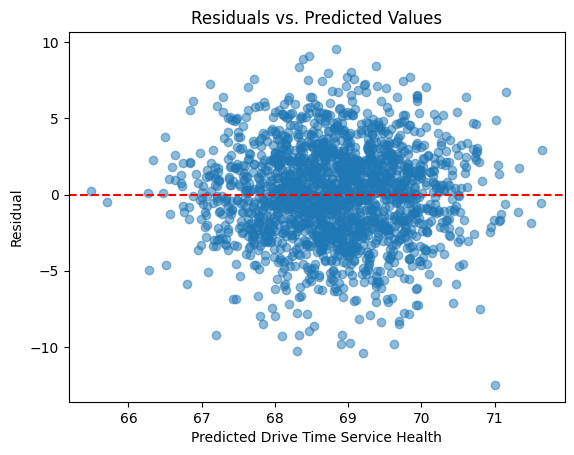

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(predicted_7, residuals_7, alpha=0.5)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Drive Time Service Health")
plt.ylabel("Residual")
plt.title("Residuals vs. Predicted Values")

plt.show()

**Residuals vs. Predicted Values**
The residual plot shows a broadly random horizontal cloud centered around zero. No strong curved pattern or funnel shape is visible, suggesting that the linear form and constant-variance assumptions are reasonably supported by visual inspection.

Several observations have relatively large positive or negative residuals, indicating days when actual Drive Time Service Health differed substantially from the model prediction. The fitted values also occupy a relatively narrow range, which is consistent with the model's limited explanatory power. The model tends to predict values near the overall average and does not capture the full range of daily variation.

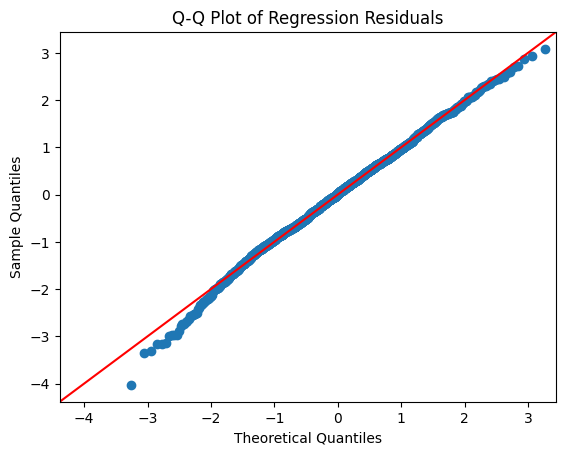

In [ ]:
sm.qqplot(residuals_7, line="45", fit=True)

plt.title("Q-Q Plot of Regression Residuals")
plt.show()

**Q-Q Plot Result**
The Q-Q plot shows that most regression residuals follow the theoretical normal-distribution line closely through the center of the distribution. The primary deviations occur in the tails, particularly in the lower tail, where one unusually negative residual is visible.

This pattern is consistent with the regression summary, which reported mild negative skew and slightly elevated kurtosis. Although formal normality tests identified a statistically significant departure from perfect normality, the visual deviation appears modest across most observations.

The residual distribution is therefore treated as approximately normal through its central range, with some tail departures and unusual observations that warrant further inspection.

**Influence Analysis**
Cook's Distance is used to identify observations that may have disproportionate influence on the fitted regression model. Large residuals are not automatically influential, so this diagnostic helps determine whether unusual observations materially affect the regression results.

In [ ]:
influence = model_7.get_influence()
cooks_distance = influence.cooks_distance[0]

In [ ]:
cooks_distance.shape

(1821,)

In [ ]:
pd.Series(cooks_distance).describe()

,0
count,1.821000e+03
mean,5.379963e-04
std,8.972858e-04
min,7.707463e-12
25%,4.688992e-05
50%,2.120378e-04
75%,6.406364e-04
max,1.097670e-02


In [ ]:
cooks_threshold = 4 / len(open_store)

cooks_threshold

0.002196595277320154

In [ ]:
influential_mask = cooks_distance > cooks_threshold

influential_mask.sum()

np.int64(90)

In [ ]:
influence_table = open_store[
    [
        "Date",
        "RetailEvent",
        "DriveTimeServiceHealth",
        "StaffingPercent",
        "SCOWaitTime",
        "CallOffCount"
    ]
].copy()

influence_table["Predicted"] = predicted_7
influence_table["Residual"] = residuals_7
influence_table["CooksDistance"] = cooks_distance

influence_table.sort_values(
    "CooksDistance",
    ascending=False
).head(10)

,Date,RetailEvent,DriveTimeServiceHealth,StaffingPercent,SCOWaitTime,CallOffCount,Predicted,Residual,CooksDistance
248,2021-09-06,Labor Day,58.5,102.2,2.4,1,71.003973,-12.503973,0.010977
1592,2025-05-12,No Retail Event,77.6,95.9,3.9,4,68.470083,9.129917,0.009817
1798,2025-12-04,No Retail Event,77.3,94.6,3.6,5,68.386178,8.913822,0.008797
949,2023-08-08,No Retail Event,58.0,96.4,3.2,4,68.297542,-10.297542,0.006803
637,2022-09-30,No Retail Event,76.1,98.7,4.1,5,68.648869,7.451131,0.006698
625,2022-09-18,No Retail Event,62.7,100.0,2.3,3,69.958437,-7.258437,0.005932
506,2022-05-22,No Retail Event,59.8,99.2,2.8,4,69.625405,-9.825405,0.005768
137,2021-05-18,No Retail Event,75.6,99.6,3.7,0,68.858966,6.741034,0.005643
999,2023-09-27,No Retail Event,77.9,100.9,2.5,3,71.148726,6.751274,0.005482
555,2022-07-10,No Retail Event,59.1,94.8,2.9,7,68.901491,-9.801491,0.005450


**Influential Observation Review**
Ninety observations exceeded the 4/n Cook's Distance screening threshold. Inspection of the ten largest values did not reveal obvious data errors. The observations occurred across multiple years and contained plausible staffing, SCO wait, call-off, and Service Health values.

The most influential observation had a Cook's Distance of approximately 0.011. These observations appear influential because their actual Service Health values differed substantially from model predictions, not because the records were clearly invalid.

The observations are therefore retained in the primary analysis. A sensitivity model will be fitted without the flagged observations only to determine whether the main coefficient directions and conclusions remain stable.

In [ ]:
sensitivity_data = open_store.loc[~influential_mask].copy()

sensitivity_data.shape

(1731, 89)

In [ ]:
X_sensitivity = sensitivity_data[predictors_7]
X_sensitivity = sm.add_constant(X_sensitivity)

y_sensitivity = sensitivity_data["DriveTimeServiceHealth"]

model_sensitivity = sm.OLS(
    y_sensitivity,
    X_sensitivity
).fit()

print(model_sensitivity.summary())

                              OLS Regression Results                              
Dep. Variable:     DriveTimeServiceHealth   R-squared:                       0.096
Model:                                OLS   Adj. R-squared:                  0.093
Method:                     Least Squares   F-statistic:                     26.25
Date:                    Mon, 16 Nov 2026   Prob (F-statistic):           2.41e-34
Time:                            22:36:06   Log-Likelihood:                -4199.3
No. Observations:                    1731   AIC:                             8415.
Df Residuals:                        1723   BIC:                             8458.
Df Model:                               7                                         
Covariance Type:                nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------

**Cook's Distance Sensitivity Result**
Ninety observations exceeded the 4/n Cook's Distance screening threshold. Because inspection did not reveal obvious data errors, these observations were retained in the primary analysis.

A sensitivity model was fitted after temporarily excluding the flagged observations. R² increased from 0.075 to 0.096, while adjusted R² increased from 0.071 to 0.093. This improvement was expected because the sensitivity dataset excluded observations that were comparatively difficult for the model to explain.

The main coefficient conclusions remained stable. StaffingPercent remained positive and statistically significant, while SCOWaitTime remained negative and statistically significant. Their coefficient sizes and confidence intervals changed only slightly.

The sensitivity analysis therefore indicates that the principal regression findings are not driven by the flagged observations. The complete 1,821-observation model remains the primary model, while the reduced dataset is retained only as a robustness check.

**6. Python Results Summary**
The key findings from the Python analysis are consolidated below to compare the original and preferred regression models and document the effects of feature reduction and sensitivity testing.

In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "8-Feature Model",
        "7-Feature Preferred Model",
        "Sensitivity Model"
    ],
    "Observations": [
        int(model.nobs),
        int(model_7.nobs),
        int(model_sensitivity.nobs)
    ],
    "R_Squared": [
        model.rsquared,
        model_7.rsquared,
        model_sensitivity.rsquared
    ],
    "Adjusted_R_Squared": [
        model.rsquared_adj,
        model_7.rsquared_adj,
        model_sensitivity.rsquared_adj
    ],
    "AIC": [
        model.aic,
        model_7.aic,
        model_sensitivity.aic
    ],
    "BIC": [
        model.bic,
        model_7.bic,
        model_sensitivity.bic
    ]
})

model_comparison.round(3)

,Model,Observations,R_Squared,Adjusted_R_Squared,AIC,BIC
0,8-Feature Model,1821,0.075,0.070,9310.265,9359.829
1,7-Feature Preferred Model,1821,0.075,0.071,9308.284,9352.341
2,Sensitivity Model,1731,0.096,0.093,8414.588,8458.239


In [ ]:
confidence_intervals = model_7.conf_int()

coefficient_table = pd.DataFrame({
    "Variable": model_7.params.index,
    "Coefficient": model_7.params.values,
    "Std_Error": model_7.bse.values,
    "P_Value": model_7.pvalues.values,
    "CI_Lower_95": confidence_intervals[0].values,
    "CI_Upper_95": confidence_intervals[1].values
})

coefficient_table.round(4)

,Variable,Coefficient,Std_Error,P_Value,CI_Lower_95,CI_Upper_95
0,const,45.9792,5.4139,0.0000,35.3611,56.5974
1,StaffingPercent,0.2112,0.0396,0.0000,0.1336,0.2888
2,SCOWaitTime,-0.8089,0.1460,0.0000,-1.0952,-0.5225
3,CallOffCount,0.0122,0.0597,0.8383,-0.1048,0.1292
4,OpenShifts,0.0203,0.0610,0.7395,-0.0994,0.1400
5,ScheduleAccuracy,0.0035,0.0359,0.9218,-0.0669,0.0739
6,AssociateEngagement,0.0299,0.0192,0.1188,-0.0077,0.0675
7,StoreExecutionScore,0.0285,0.0207,0.1687,-0.0121,0.0691


**7. Python Analysis Conclusion**
Python independently confirmed the dataset structure, intentional Christmas closure missingness, and selected correlations previously identified in Orange Data Mining.

The initial eight-feature multiple regression explained approximately 7.5% of the in-sample variation in DriveTimeServiceHealth. VIF analysis identified substantial overlap involving LaborVariance. Removing LaborVariance produced a simpler seven-feature model with the same displayed R², a slightly higher adjusted R², lower AIC and BIC, and substantially reduced VIF values.

In the preferred seven-feature model, StaffingPercent had a statistically significant positive coefficient, while SCOWaitTime had a statistically significant negative coefficient. These directions remained stable across Orange exploration, Python correlation analysis, multiple regression, feature reduction, and Cook's Distance sensitivity testing.

The remaining predictors did not show statistically significant unique adjusted effects. This does not establish that they are operationally irrelevant, but the model did not provide sufficient evidence of separate contributions after the other variables were controlled.

Residual diagnostics showed no obvious strong curvature or funnel pattern. The residual distribution followed the normal reference line reasonably well through the center, with mild tail departures and several unusual observations.

Cook's Distance identified 90 observations above the 4/n screening threshold. Inspection did not reveal obvious data errors, so these records were retained. A sensitivity model excluding the flagged observations produced stable StaffingPercent and SCOWaitTime coefficients, indicating that the main conclusions were not driven by those observations.

Overall, Python strengthened the Orange findings by independently reproducing selected relationships and adding statistical significance testing, confidence intervals, multicollinearity diagnostics, residual analysis, and influence sensitivity testing. The preferred model remains limited in explanatory power, indicating that substantial daily variation in Drive Time Service Health is not captured by the available aggregate operational variables.